# Exploratory data analysis

This notebook only draws pictures of the cleaned table.
It does not scale columns, split the rows, train a model, or change the uneven purchase split.

Every chart is saved at 150 dpi under `images/` and uses the values as they are stored.
A log scale, where it appears, is for the picture only.


### Load the cleaned file

`read_csv` turns the four code columns back into numbers. We cast them to text immediately.
`month_order` is the same Jan-to-Dec list used in the cleaning notebook. January and April are in that list and are absent from the file.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

np.random.seed(42)
sns.set_theme(style="whitegrid")

if Path("data/processed/cleaned_shoppers.csv").exists():
    cleaned_path = Path("data/processed/cleaned_shoppers.csv")
    image_dir = Path("images")
else:
    cleaned_path = Path("../data/processed/cleaned_shoppers.csv")
    image_dir = Path("../images")

image_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(cleaned_path)
code_columns = ["OperatingSystems", "Browser", "Region", "TrafficType"]
for column in code_columns:
    df[column] = df[column].astype(str)

month_order = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec",
]
present_months = [month for month in month_order if (df["Month"] == month).any()]
df["Month"] = pd.Categorical(df["Month"], categories=present_months, ordered=True)

assert len(df) == 12205
assert int(df.isna().sum().sum()) == 0
print("Rows:", len(df))
print("Missing cells:", int(df.isna().sum().sum()))
print("Months in calendar order:", present_months)
print("Absent from month_order:", [month for month in month_order if month not in present_months])


def save_and_show(fig, name):
    # name is the file stem after 02_.
    path = image_dir / f"02_{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("Saved:", path)
    plt.show()


Rows: 12205
Missing cells: 0
Months in calendar order: ['Feb', 'Mar', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
Absent from month_order: ['Jan', 'Apr']


The file has **12,205** rows and **0** missing cells. The months present, in calendar order, are Feb through Dec except April. January and April are absent.


### 1. Did the visitor buy?

`Revenue` is 1 for a purchase and 0 otherwise. This chart only counts. It does not rebalance the classes.


Revenue
0    10297
1     1908
Revenue
0    84.37
1    15.63
Saved: ../images/02_revenue_counts.png


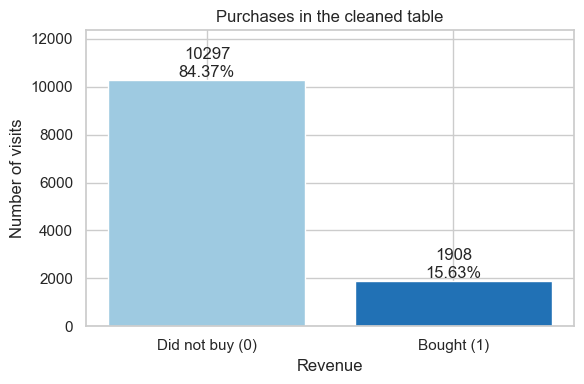

In [2]:
revenue_counts = df["Revenue"].value_counts().sort_index()
revenue_percent = 100 * revenue_counts / len(df)
print(revenue_counts.to_string())
print(revenue_percent.round(2).to_string())

fig, ax = plt.subplots(figsize=(6, 4))
labels = ["Did not buy (0)", "Bought (1)"]
bars = ax.bar(labels, revenue_counts.values, color=["#9ecae1", "#2171b5"])
for bar, count, percent in zip(bars, revenue_counts.values, revenue_percent.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(count)}\n{percent:.2f}%",
        ha="center",
        va="bottom",
    )
ax.set_ylabel("Number of visits")
ax.set_xlabel("Revenue")
ax.set_title("Purchases in the cleaned table")
ax.set_ylim(0, revenue_counts.max() * 1.2)
fig.tight_layout()
save_and_show(fig, "revenue_counts")


Of the **12,205** visits, **1,908** bought (**15.63%**) and **10,297** did not (**84.37%**). The classes stay uneven. This notebook does not change that.


### 2. Histograms of the numeric columns

The title of each panel is the percent of zeros. A log scale on the count axis is display only, and only where the raw counts would hide the tail. The table is not changed.


Percent of zeros:
  Administrative: 46.24%
  Administrative_Duration: 47.34%
  Informational: 78.44%
  Informational_Duration: 80.29%
  ProductRelated: 0.31%
  ProductRelated_Duration: 5.16%
  BounceRates: 45.21%
  ExitRates: 0.62%
  PageValues: 77.63%
  SpecialDay: 89.77%
  Weekend: 76.58%
  Revenue: 84.37%


Saved: ../images/02_histograms_numeric.png


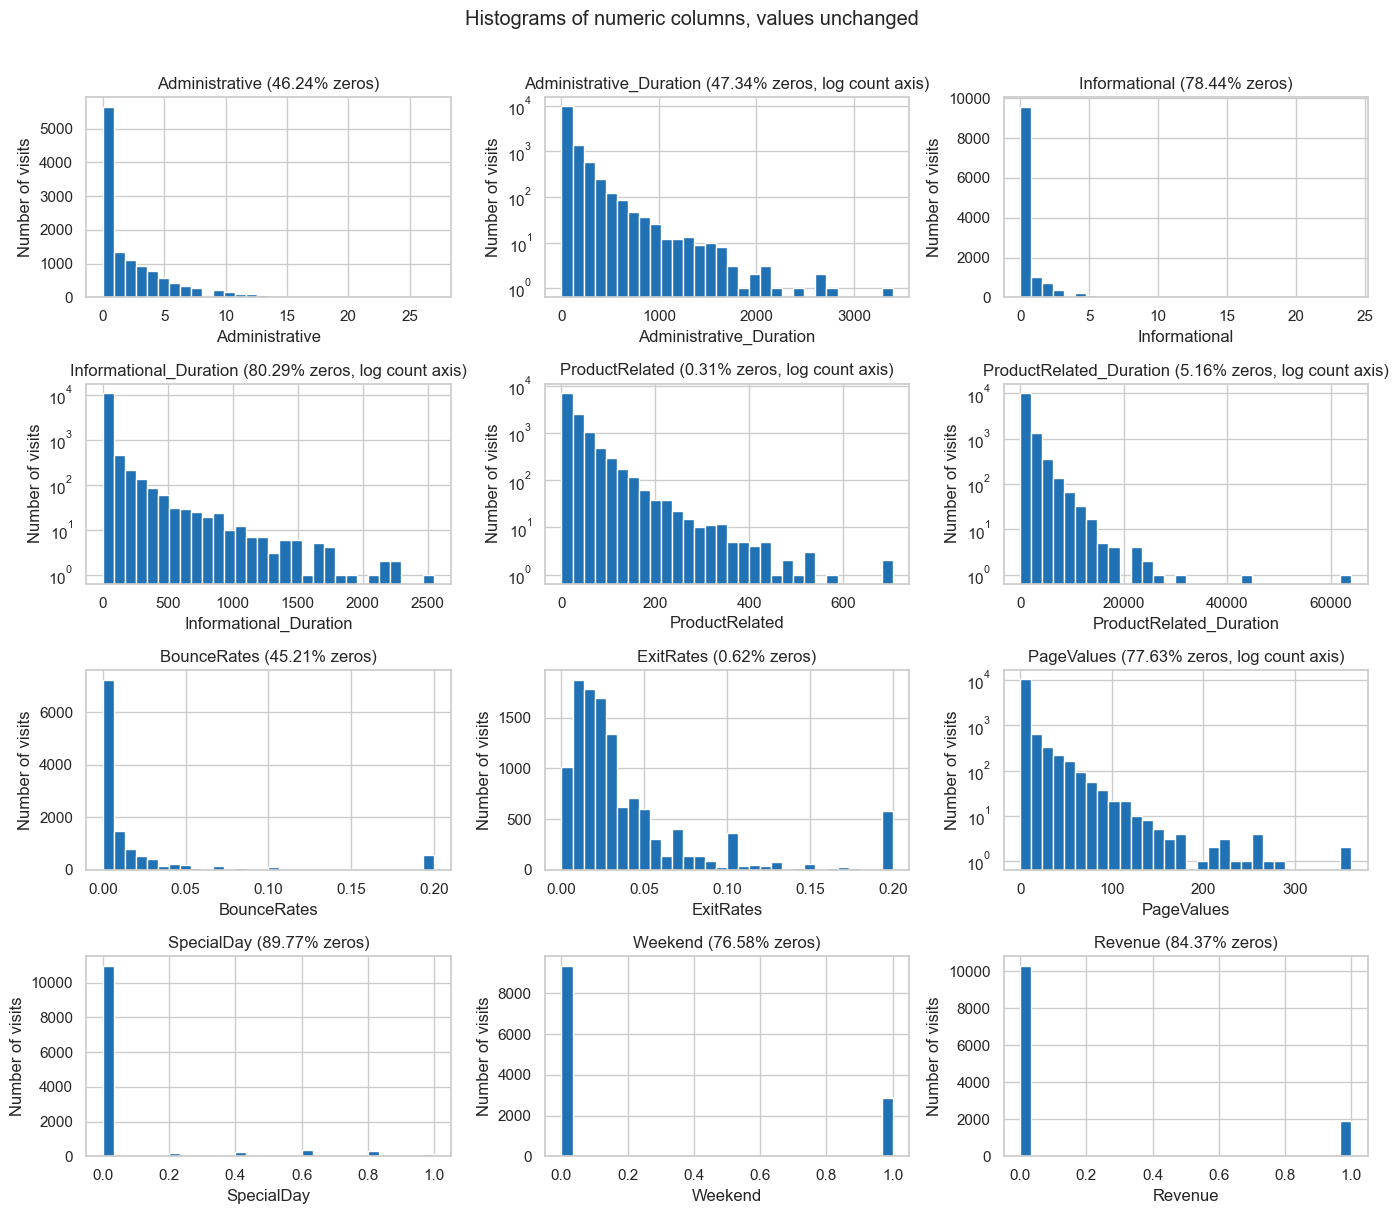

In [3]:
number_columns = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay",
    "Weekend",
    "Revenue",
]
# These columns run into the hundreds or thousands, so a log count axis shows the tail.
log_count_columns = {
    "Administrative_Duration",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "PageValues",
}

print("Percent of zeros:")
for column in number_columns:
    percent_zero = 100 * (df[column] == 0).mean()
    print(f"  {column}: {percent_zero:.2f}%")

fig, axes = plt.subplots(4, 3, figsize=(14, 12))
for ax, column in zip(axes.ravel(), number_columns):
    percent_zero = 100 * (df[column] == 0).mean()
    ax.hist(df[column], bins=30, color="#2171b5")
    if column in log_count_columns:
        ax.set_yscale("log")
        scale_note = ", log count axis"
    else:
        scale_note = ""
    ax.set_title(f"{column} ({percent_zero:.2f}% zeros{scale_note})")
    ax.set_xlabel(column)
    ax.set_ylabel("Number of visits")
fig.suptitle("Histograms of numeric columns, values unchanged", y=1.01)
fig.tight_layout()
save_and_show(fig, "histograms_numeric")


`SpecialDay` is 0 on **89.77%** of rows, `Informational_Duration` on **80.29%**, and `PageValues` on **77.63%**. `ProductRelated` is 0 on only **0.31%** of rows, and `ExitRates` on **0.62%**. `Revenue` is 0 on **84.37%** of rows, which is the same 10,297 non-buyers as the bar chart.


### 3. Boxplots

Each numeric column gets its own raw scale, so a long duration does not flatten the other boxes.
The second figure compares buyers and non-buyers on the columns with a real tail or a strong link to purchase. `log1p` on an axis is display only.


Saved: ../images/02_boxplots_numeric.png


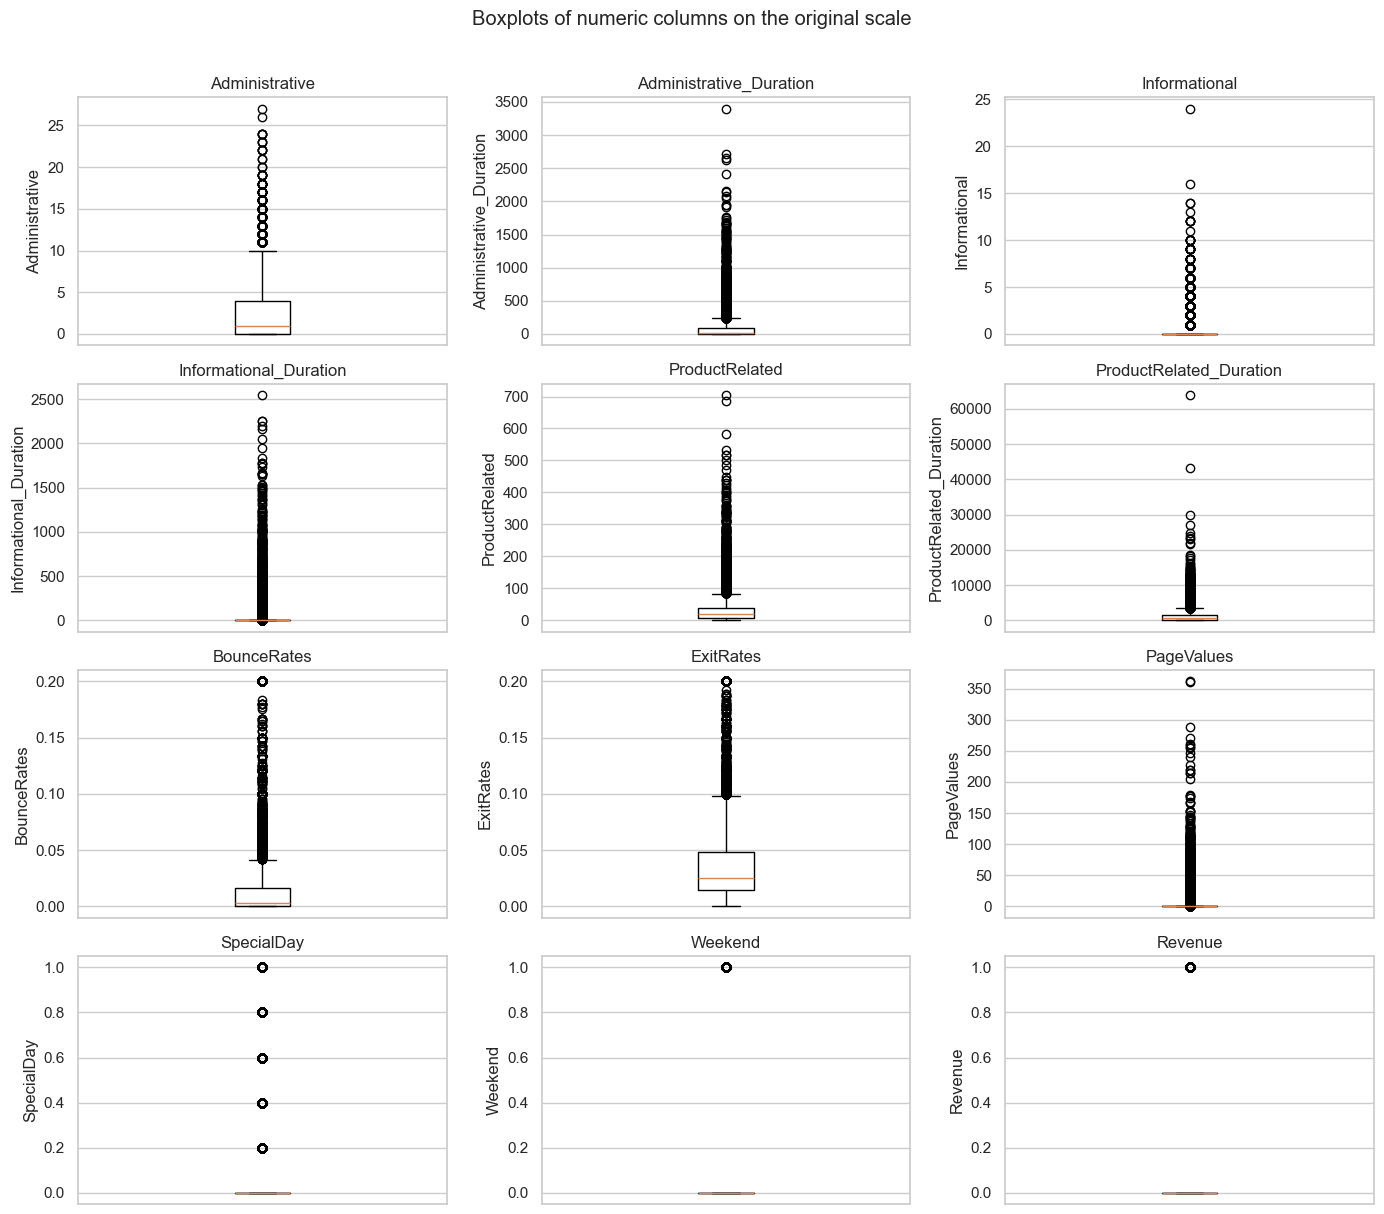

Median by Revenue. This print does not change the table:
  Administrative_Duration, Revenue 0: 0.00
  Administrative_Duration, Revenue 1: 52.37
  ProductRelated, Revenue 0: 16.00
  ProductRelated, Revenue 1: 29.00
  ProductRelated_Duration, Revenue 0: 526.00
  ProductRelated_Duration, Revenue 1: 1109.91
  PageValues, Revenue 0: 0.00
  PageValues, Revenue 1: 16.76
  BounceRates, Revenue 0: 0.00
  BounceRates, Revenue 1: 0.00
  ExitRates, Revenue 0: 0.03
  ExitRates, Revenue 1: 0.02


Saved: ../images/02_boxplots_by_revenue.png


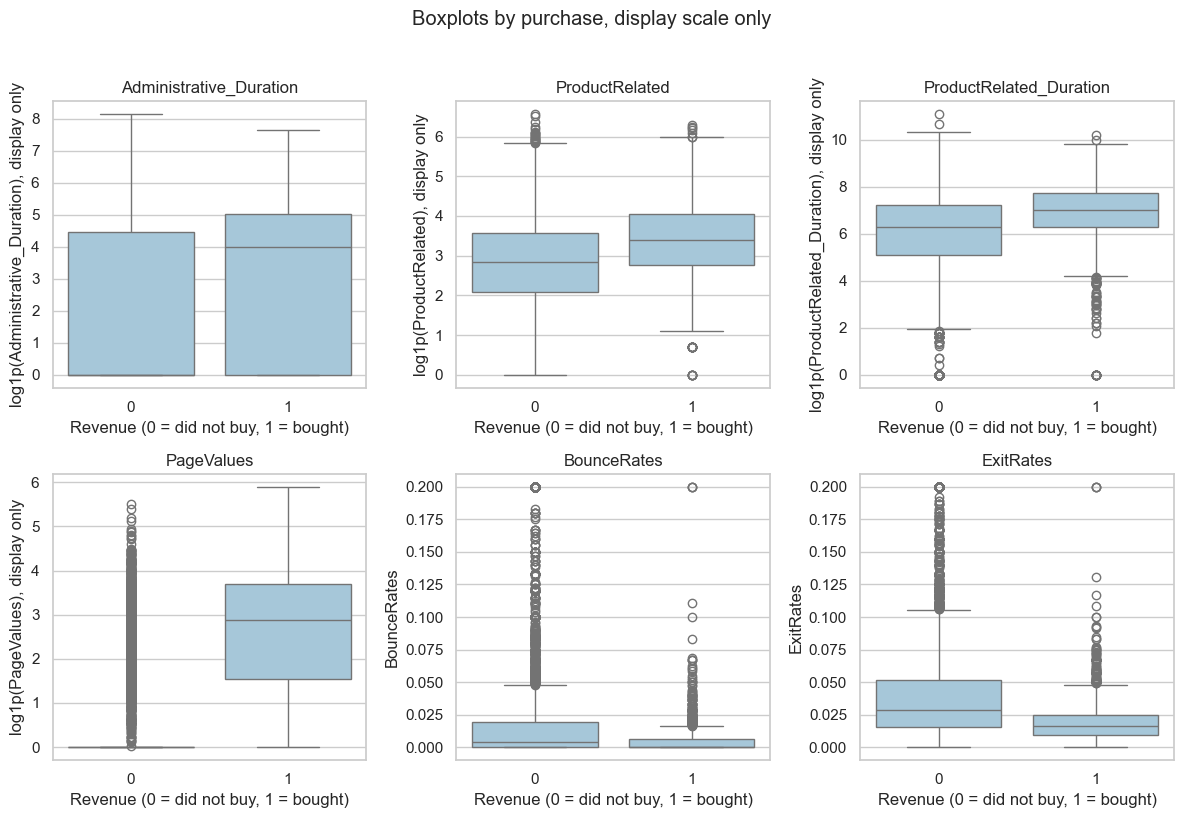

In [4]:
fig, axes = plt.subplots(4, 3, figsize=(14, 12))
for ax, column in zip(axes.ravel(), number_columns):
    ax.boxplot(df[column], vert=True, showfliers=True)
    ax.set_title(column)
    ax.set_ylabel(column)
    ax.set_xticks([])
    ax.set_xlabel("")
fig.suptitle("Boxplots of numeric columns on the original scale", y=1.01)
fig.tight_layout()
save_and_show(fig, "boxplots_numeric")

key_columns = [
    "Administrative_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "PageValues",
    "BounceRates",
    "ExitRates",
]
print("Median by Revenue. This print does not change the table:")
for column in key_columns:
    for revenue_value in [0, 1]:
        median_value = df.loc[df["Revenue"] == revenue_value, column].median()
        print(f"  {column}, Revenue {revenue_value}: {median_value:.2f}")

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, column in zip(axes.ravel(), key_columns):
    # A copy used only for the axis. df itself is not replaced.
    if df[column].max() > 1:
        shown = np.log1p(df[column])
        ylabel = f"log1p({column}), display only"
    else:
        shown = df[column]
        ylabel = column
    plot_frame = pd.DataFrame({"Revenue": df["Revenue"].astype(str), "shown": shown})
    sns.boxplot(data=plot_frame, x="Revenue", y="shown", ax=ax, color="#9ecae1")
    ax.set_title(column)
    ax.set_xlabel("Revenue (0 = did not buy, 1 = bought)")
    ax.set_ylabel(ylabel)
fig.suptitle("Boxplots by purchase, display scale only", y=1.02)
fig.tight_layout()
save_and_show(fig, "boxplots_by_revenue")


Buyers have a higher median `ProductRelated_Duration` (**1,109.91** versus **526.00**) and a higher median `PageValues` (**16.76** versus **0**). `BounceRates` has median **0** in both groups, because **45.21%** of all rows are already 0. Nothing was capped or deleted.


### 4. Correlation

The heatmap uses the numeric columns plus `Revenue`. A pair is listed when the absolute correlation is at least 0.7.
Correlation is a number from -1 to 1 that says how two columns move together. It is not proof that one causes the other.


Pairs with absolute correlation at least 0.7:
  ProductRelated and ProductRelated_Duration: 0.8603
  BounceRates and ExitRates: 0.9021
Pair count: 2


Saved: ../images/02_correlation_heatmap.png


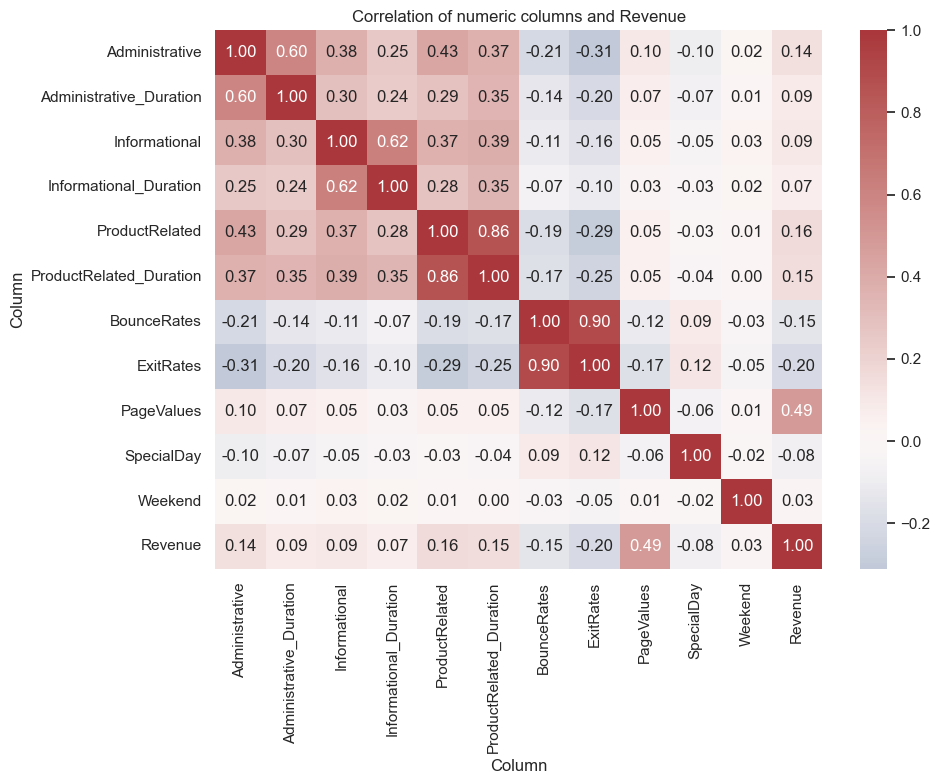

Pearson and Spearman with Revenue:
                         Pearson  Spearman
ExitRates                -0.2043   -0.2510
BounceRates              -0.1451   -0.1436
SpecialDay               -0.0836   -0.0883
Weekend                   0.0277    0.0277
Informational_Duration    0.0694    0.1102
Informational             0.0936    0.1119
Administrative_Duration   0.0918    0.1605
Administrative            0.1363    0.1645
ProductRelated            0.1560    0.1943
ProductRelated_Duration   0.1501    0.2127
PageValues                0.4919    0.6257
Saved: ../images/02_correlation_with_revenue.png


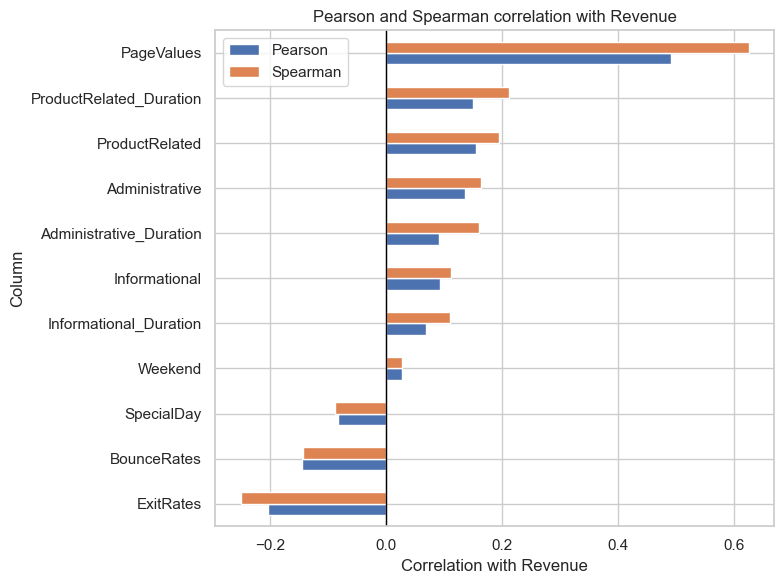

In [5]:
corr = df[number_columns].corr()
print("Pairs with absolute correlation at least 0.7:")
pair_count = 0
for left_index, left in enumerate(number_columns):
    for right in number_columns[left_index + 1 :]:
        value = corr.loc[left, right]
        if abs(value) >= 0.7:
            pair_count += 1
            print(f"  {left} and {right}: {value:.4f}")
print("Pair count:", pair_count)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Correlation of numeric columns and Revenue")
ax.set_xlabel("Column")
ax.set_ylabel("Column")
fig.tight_layout()
save_and_show(fig, "correlation_heatmap")

pearson_with_revenue = corr["Revenue"].drop("Revenue")
spearman_with_revenue = df[number_columns].corr(method="spearman")["Revenue"].drop("Revenue")
both = pd.DataFrame({"Pearson": pearson_with_revenue, "Spearman": spearman_with_revenue})
both = both.sort_values("Spearman")
print("Pearson and Spearman with Revenue:")
print(both.round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 6))
both.plot(kind="barh", ax=ax)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Correlation with Revenue")
ax.set_ylabel("Column")
ax.set_title("Pearson and Spearman correlation with Revenue")
fig.tight_layout()
save_and_show(fig, "correlation_with_revenue")


Two pairs reach absolute Pearson correlation 0.7 or more: `BounceRates` with `ExitRates` (**r = 0.90**) and `ProductRelated` with `ProductRelated_Duration` (**r = 0.86**). No third pair reaches 0.70. `PageValues` is the strongest link with `Revenue` (Pearson **0.49**, Spearman **0.63**). `ExitRates` is the strongest negative link (Pearson **-0.20**, Spearman **-0.25**). Spearman uses the order of the values rather than a straight line, so a column that is mostly zeros can still show a link.


### 5. Buying rate by group

Each bar is the percent who bought. The label is the number of rows. A gray bar has fewer than 100 rows, so that percent is unreliable.
There is no year column, and January and April are missing, so month differences are seasonality inside this file, not a trend across time.


Month
       buyers     n   rate
Month                     
Feb         3   181   1.66
Mar       192  1860  10.32
May       365  3329  10.96
Jun        29   285  10.18
Jul        66   432  15.28
Aug        76   433  17.55
Sep        86   448  19.20
Oct       115   549  20.95
Nov       760  2982  25.49
Dec       216  1706  12.66
Groups under 30 buyers: ['Feb', 'Jun']


Saved: ../images/02_buying_rate_month.png


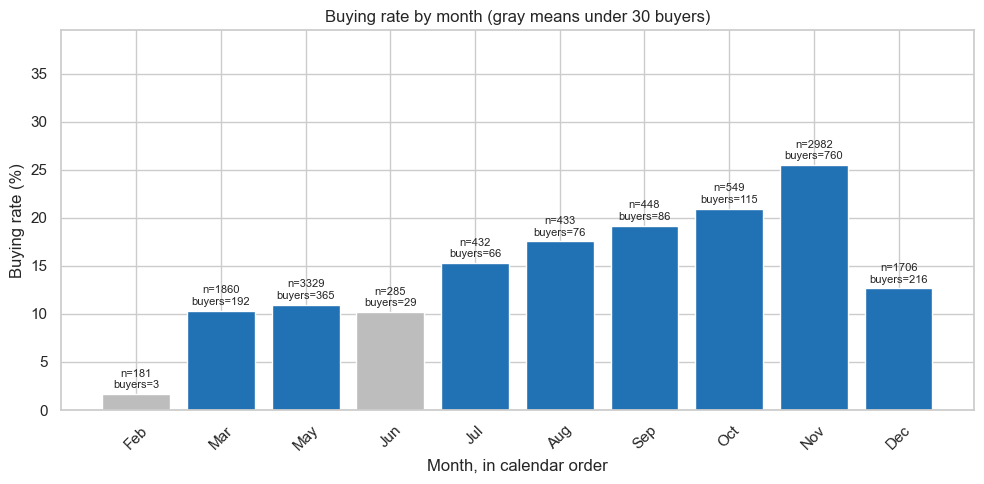

November rows: 2982 of 12205 (24.43%)
November buyers: 760 of 1908 (39.83%)


In [6]:
def buying_rate_bars(frame, column, filename, title, xlabel, order=None, min_buyers=None):
    grouped = frame.groupby(column, observed=False)["Revenue"].agg(buyers="sum", n="count")
    grouped["rate"] = 100 * grouped["buyers"] / grouped["n"]
    if order is not None:
        grouped = grouped.reindex(order).dropna(subset=["n"])
    print(column)
    print(grouped.round(2).to_string())
    if min_buyers is None:
        small = grouped.index[grouped["n"] < 100].tolist()
        print("Groups under 100 rows:", small)
        unreliable = grouped["n"] < 100
    else:
        small = grouped.index[grouped["buyers"] < min_buyers].tolist()
        print(f"Groups under {min_buyers} buyers:", small)
        unreliable = grouped["buyers"] < min_buyers

    fig, ax = plt.subplots(figsize=(10, 5))
    colors = ["#bdbdbd" if flag else "#2171b5" for flag in unreliable]
    bars = ax.bar([str(label) for label in grouped.index], grouped["rate"], color=colors)
    for bar, n_rows, buyer_count in zip(bars, grouped["n"], grouped["buyers"]):
        if min_buyers is None:
            label = f"n={int(n_rows)}"
        else:
            label = f"n={int(n_rows)}\nbuyers={int(buyer_count)}"
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.4,
            label,
            ha="center",
            va="bottom",
            fontsize=8,
        )
    ax.set_ylabel("Buying rate (%)")
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    top = grouped["rate"].max()
    if min_buyers is None:
        ax.set_ylim(0, max(top * 1.25, 5))
    else:
        ax.set_ylim(0, max(top * 1.55, 5))
    ax.tick_params(axis="x", labelrotation=45)
    fig.tight_layout()
    save_and_show(fig, filename)
    return grouped


buying_rate_bars(
    df,
    "Month",
    "buying_rate_month",
    "Buying rate by month (gray means under 30 buyers)",
    "Month, in calendar order",
    order=present_months,
    min_buyers=30,
)

november = df["Month"] == "Nov"
nov_rows = int(november.sum())
nov_buyers = int(df.loc[november, "Revenue"].sum())
all_buyers = int(df["Revenue"].sum())
print("November rows:", nov_rows, "of", len(df), "({:.2f}%)".format(100 * nov_rows / len(df)))
print("November buyers:", nov_buyers, "of", all_buyers, "({:.2f}%)".format(100 * nov_buyers / all_buyers))


November has the highest buying rate, **25.49%** (760 buyers, n = **2,982**). Those 2,982 rows are **24.43%** of all 12,205 visits, and those 760 buyers are **39.83%** of all 1,908 buyers. February has **3** buyers in 181 rows, and June has **29** buyers in 285 rows, so both bars are gray. A month is unreliable here when it has under 30 buyers. January and April are absent, and there is no year, so this is seasonality, not a trend.


VisitorType
                   buyers      n   rate
VisitorType                            
New_Visitor           422   1693  24.93
Returning_Visitor    1470  10431  14.09
Other                  16     81  19.75
Groups under 100 rows: ['Other']
Saved: ../images/02_buying_rate_visitor_type.png


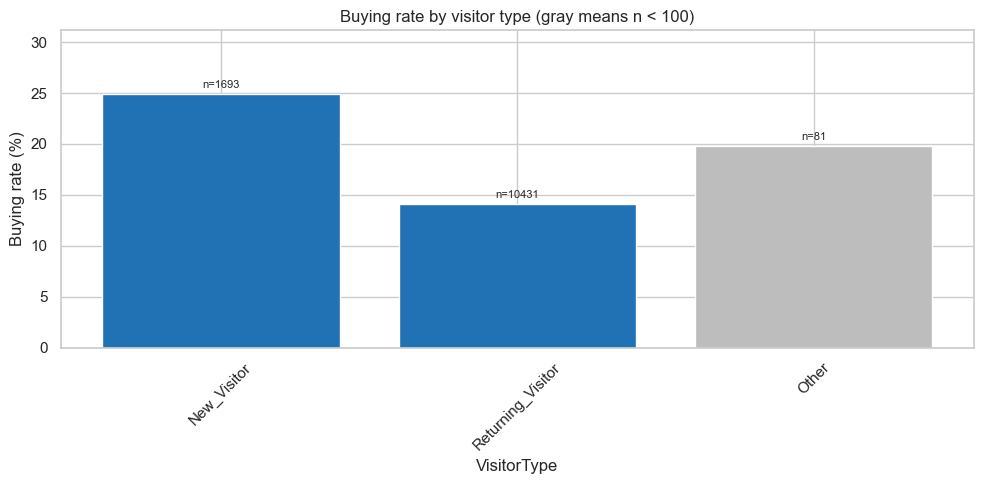

,buyers,n,rate
VisitorType,,,
New_Visitor,422,1693,24.926167
Returning_Visitor,1470,10431,14.092609
Other,16,81,19.753086


In [7]:
buying_rate_bars(
    df,
    "VisitorType",
    "buying_rate_visitor_type",
    "Buying rate by visitor type (gray means n < 100)",
    "VisitorType",
    order=["New_Visitor", "Returning_Visitor", "Other"],
)


New visitors buy at **24.93%** (n = **1,693**). Returning visitors buy at **14.09%** (n = **10,431**). `Other` is **19.75%**, but n = **81**, so that bar is gray and the percent is unreliable.


Weekend
         buyers     n   rate
Weekend                     
0          1409  9346  15.08
1           499  2859  17.45
Groups under 100 rows: []


Saved: ../images/02_buying_rate_weekend.png


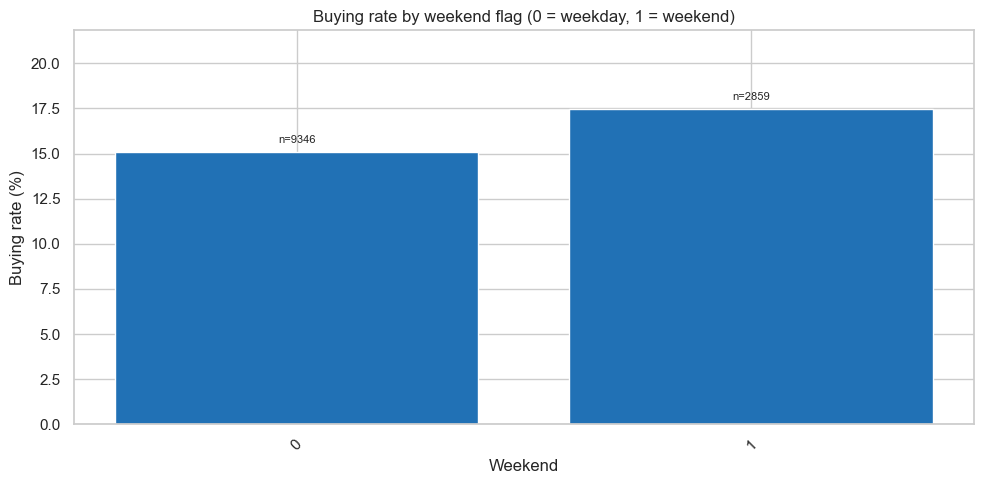

,buyers,n,rate
Weekend,,,
0,1409,9346,15.075968
1,499,2859,17.453655


In [8]:
buying_rate_bars(
    df,
    "Weekend",
    "buying_rate_weekend",
    "Buying rate by weekend flag (0 = weekday, 1 = weekend)",
    "Weekend",
    order=[0, 1],
)


Weekend visits buy at **17.45%** (n = **2,859**). Weekday visits buy at **15.08%** (n = **9,346**). Both groups are far above 100 rows, so the small gap is measured on large groups.


SpecialDay
            buyers      n   rate
SpecialDay                      
0.0           1831  10956  16.71
0.2             14    178   7.87
0.4             13    243   5.35
0.6             29    350   8.29
0.8             11    324   3.40
1.0             10    154   6.49
Groups under 100 rows: []


Saved: ../images/02_buying_rate_special_day.png


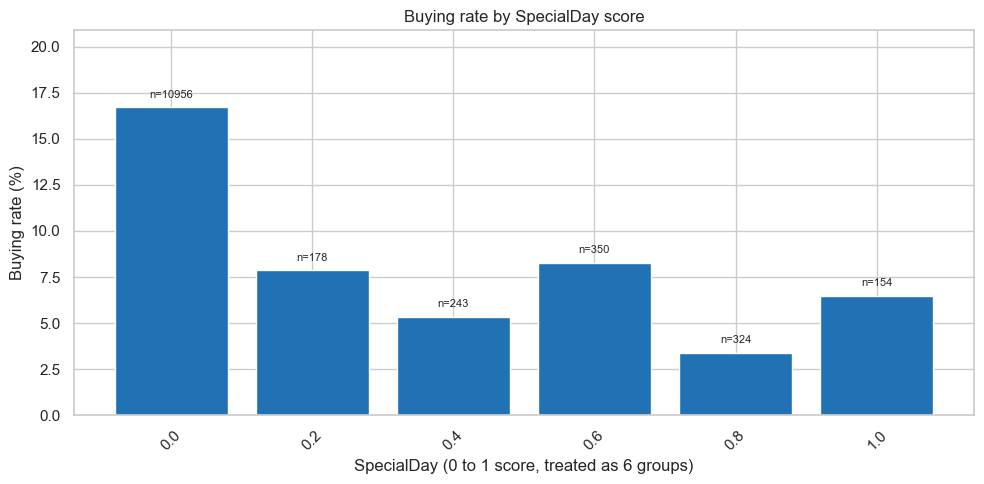

,buyers,n,rate
SpecialDay,,,
0.0,1831,10956,16.712304
0.2,14,178,7.865169
0.4,13,243,5.349794
0.6,29,350,8.285714
0.8,11,324,3.395062
1.0,10,154,6.493506


In [9]:
buying_rate_bars(
    df,
    "SpecialDay",
    "buying_rate_special_day",
    "Buying rate by SpecialDay score",
    "SpecialDay (0 to 1 score, treated as 6 groups)",
    order=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0],
)


In [10]:
special_group = pd.Series("zero", index=df.index)
special_group.loc[df["SpecialDay"] > 0] = "nonzero"
special_by_month = pd.crosstab(df["Month"], special_group)
print("SpecialDay zero versus nonzero, by month:")
print(special_by_month.to_string())
nonzero_months = special_by_month.index[special_by_month["nonzero"] > 0].tolist()
print("Months with a nonzero SpecialDay:", [str(month) for month in nonzero_months])

for month in nonzero_months:
    month_rows = df[df["Month"] == month]
    print("Month", month, "rows", len(month_rows), "buyers", int(month_rows["Revenue"].sum()))
    for label, mask in [("zero", month_rows["SpecialDay"] == 0), ("nonzero", month_rows["SpecialDay"] > 0)]:
        part = month_rows.loc[mask]
        buyers = int(part["Revenue"].sum())
        rate = 100 * buyers / len(part)
        print(f"  {label}: n={len(part)}, buyers={buyers}, rate={rate:.2f}%")


SpecialDay zero versus nonzero, by month:
col_0  nonzero  zero
Month               
Feb         79   102
Mar          0  1860
May       1170  2159
Jun          0   285
Jul          0   432
Aug          0   433
Sep          0   448
Oct          0   549
Nov          0  2982
Dec          0  1706
Months with a nonzero SpecialDay: ['Feb', 'May']
Month Feb rows 181 buyers 3
  zero: n=102, buyers=1, rate=0.98%
  nonzero: n=79, buyers=2, rate=2.53%
Month May rows 3329 buyers 365
  zero: n=2159, buyers=290, rate=13.43%
  nonzero: n=1170, buyers=75, rate=6.41%


Nonzero `SpecialDay` scores sit in only two months: February (**79** rows) and May (**1,170** rows). The all-year chart puts those rows against every other month, including November, which has no special-day score and a high buying rate.

Inside May, a score of 0 buys at **13.43%** (290 buyers, n = **2,159**) and a nonzero score buys at **6.41%** (75 buyers, n = **1,170**). February has only **3** buyers in the whole month, so its 0.98% versus 2.53% split is unreliable. The all-year gap, 16.71% versus 6.16%, is not a clean SpecialDay effect.


TrafficType
             buyers     n   rate
TrafficType                     
1               262  2388  10.97
2               847  3911  21.66
3               180  2013   8.94
4               165  1066  15.48
5                56   260  21.54
6                53   443  11.96
7                12    40  30.00
8                95   343  27.70
9                 4    41   9.76
10               90   450  20.00
11               47   247  19.03
12                0     1   0.00
13               43   728   5.91
14                2    13  15.38
15                0    37   0.00
16                1     3  33.33
17                0     1   0.00
18                0    10   0.00
19                1    17   5.88
20               50   193  25.91
Groups under 100 rows: ['7', '9', '12', '14', '15', '16', '17', '18', '19']


Saved: ../images/02_buying_rate_traffic_type.png


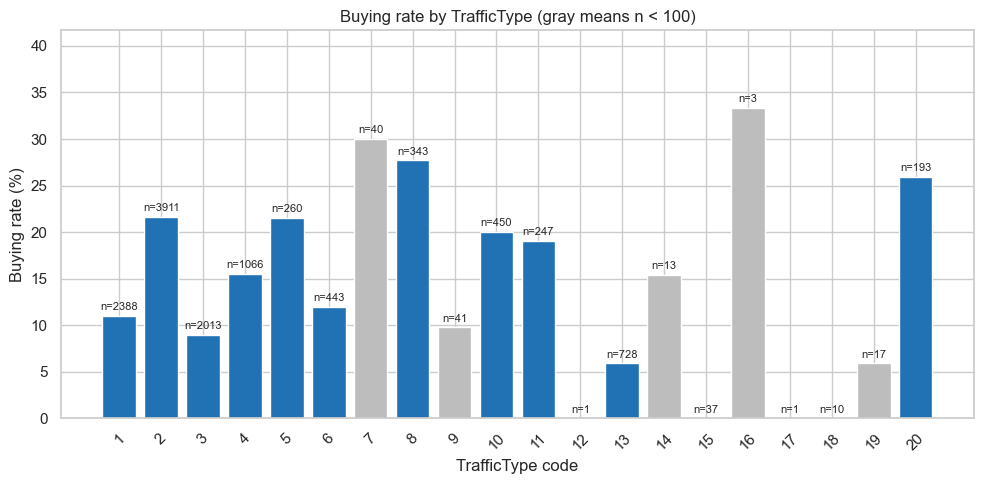

,buyers,n,rate
TrafficType,,,
1,262,2388,10.971524
2,847,3911,21.656865
3,180,2013,8.941878
4,165,1066,15.478424
5,56,260,21.538462
6,53,443,11.963883
7,12,40,30.000000
8,95,343,27.696793
9,4,41,9.756098


In [11]:
traffic_order = sorted(df["TrafficType"].unique(), key=lambda value: int(value))
buying_rate_bars(
    df,
    "TrafficType",
    "buying_rate_traffic_type",
    "Buying rate by TrafficType (gray means n < 100)",
    "TrafficType code",
    order=traffic_order,
)


Among codes with at least 100 rows, code **8** buys at **27.70%** (n = **343**) and code **13** buys at **5.91%** (n = **728**). Code **2** is the largest source, at **21.66%** (n = **3,911**). Codes 7, 9, 12, 14, 15, 16, 17, 18, and 19 have fewer than 100 rows, so those percents are unreliable.


Region
        buyers     n   rate
Region                     
1          771  4714  16.36
2          188  1128  16.67
3          349  2379  14.67
4          175  1171  14.94
5           52   318  16.35
6          112   801  13.98
7          119   758  15.70
8           56   431  12.99
9           86   505  17.03
Groups under 100 rows: []


Saved: ../images/02_buying_rate_region.png


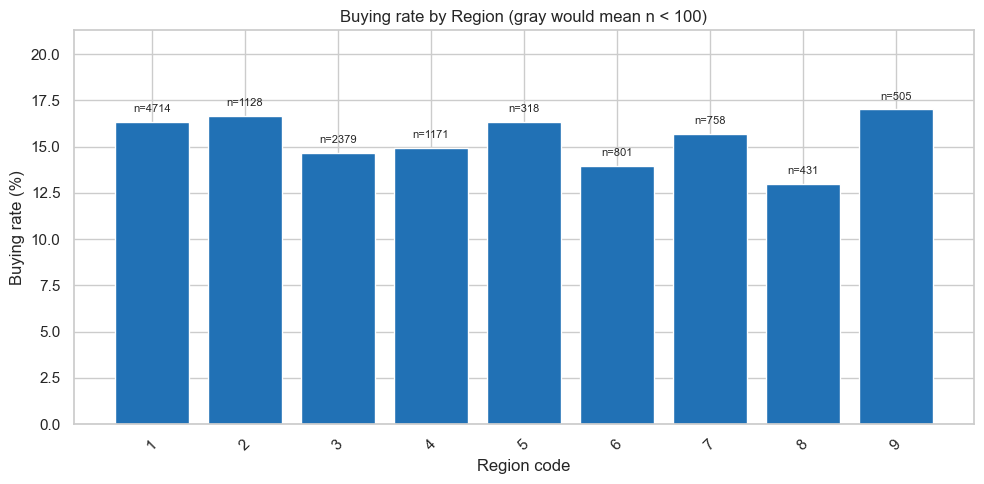

,buyers,n,rate
Region,,,
1,771,4714,16.355537
2,188,1128,16.666667
3,349,2379,14.670029
4,175,1171,14.944492
5,52,318,16.352201
6,112,801,13.982522
7,119,758,15.699208
8,56,431,12.993039
9,86,505,17.029703


In [12]:
region_order = sorted(df["Region"].unique(), key=lambda value: int(value))
buying_rate_bars(
    df,
    "Region",
    "buying_rate_region",
    "Buying rate by Region (gray would mean n < 100)",
    "Region code",
    order=region_order,
)


Region buying rates only run from **12.99%** in region 8 (n = **431**) to **17.03%** in region 9 (n = **505**). Every region has at least 100 rows.


### 6. Page count above 0 and time equal to 0

For each page type, the blue comparison is rows with a page count above 0 and a recorded time of 0, against every other row. The table is not filled or changed.


     page_type      group     n  buyers  buying_rate
Administrative  zero time   135      34        25.19
Administrative other rows 12070    1874        15.53
 Informational  zero time   226      48        21.24
 Informational other rows 11979    1860        15.53
ProductRelated  zero time   592       7         1.18
ProductRelated other rows 11613    1901        16.37


Saved: ../images/02_buying_rate_zero_time.png


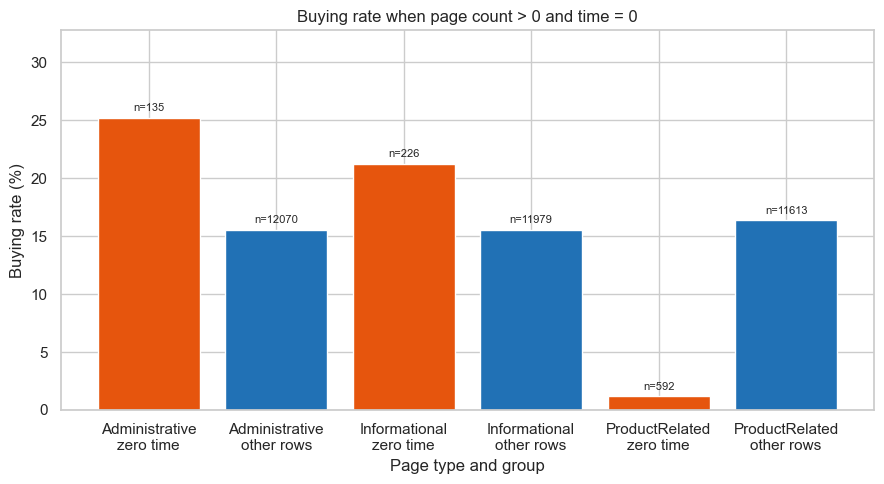

In [13]:
page_time_pairs = [
    ("Administrative", "Administrative_Duration"),
    ("Informational", "Informational_Duration"),
    ("ProductRelated", "ProductRelated_Duration"),
]
zero_time_rows = []
for pages, duration in page_time_pairs:
    zero_time_mask = (df[pages] > 0) & (df[duration] == 0)
    for group_name, part in [("zero time", df.loc[zero_time_mask]), ("other rows", df.loc[~zero_time_mask])]:
        n_rows = len(part)
        buyers = int(part["Revenue"].sum())
        zero_time_rows.append(
            {
                "page_type": pages,
                "group": group_name,
                "n": n_rows,
                "buyers": buyers,
                "buying_rate": round(100 * buyers / n_rows, 2),
            }
        )

zero_time_table = pd.DataFrame(zero_time_rows)
print(zero_time_table.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
labels = []
rates = []
colors = []
ns = []
for row in zero_time_rows:
    labels.append(f"{row['page_type']}\n{row['group']}")
    rates.append(row["buying_rate"])
    ns.append(row["n"])
    colors.append("#e6550d" if row["group"] == "zero time" else "#2171b5")
bars = ax.bar(labels, rates, color=colors)
for bar, n_rows in zip(bars, ns):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.4,
        f"n={n_rows}",
        ha="center",
        va="bottom",
        fontsize=8,
    )
ax.set_ylabel("Buying rate (%)")
ax.set_xlabel("Page type and group")
ax.set_title("Buying rate when page count > 0 and time = 0")
ax.set_ylim(0, max(rates) * 1.3)
fig.tight_layout()
save_and_show(fig, "buying_rate_zero_time")


These three page types do not tell the same story. Administrative zero-time rows buy at **25.19%** (n = **135**) against **15.53%** for the other rows (n = **12,070**). Informational zero-time rows buy at **21.24%** (n = **226**) against **15.53%** (n = **11,979**). ProductRelated pages above 0 with time equal to 0: **7** buyers in **592** rows (**1.18%**), against **16.37%** for the other rows (n = **11,613**).


### 7. BounceRates and ExitRates

The black line is y = x. Points above that line have BounceRates greater than ExitRates. The count is taken on this cleaned table.


Cleaned rows: 12205
BounceRates > ExitRates on the cleaned table: 175


Saved: ../images/02_bounce_vs_exit.png


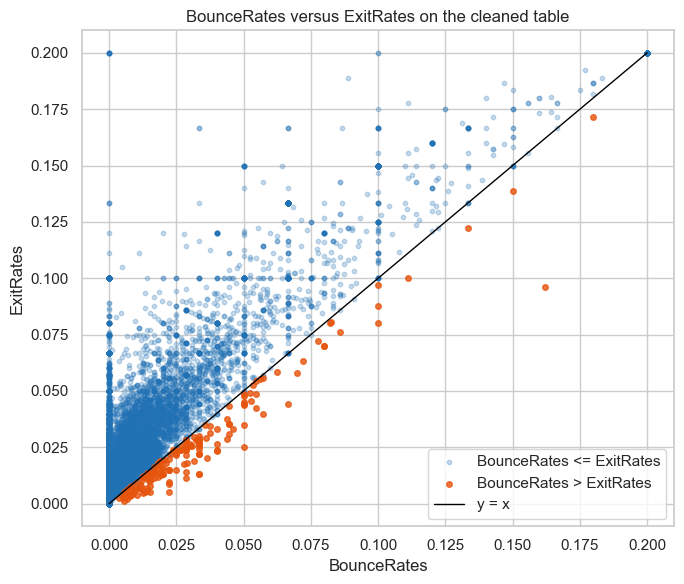

In [14]:
above_line = df["BounceRates"] > df["ExitRates"]
print("Cleaned rows:", len(df))
print("BounceRates > ExitRates on the cleaned table:", int(above_line.sum()))

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(
    df.loc[~above_line, "BounceRates"],
    df.loc[~above_line, "ExitRates"],
    s=10,
    alpha=0.25,
    label="BounceRates <= ExitRates",
    color="#2171b5",
)
ax.scatter(
    df.loc[above_line, "BounceRates"],
    df.loc[above_line, "ExitRates"],
    s=16,
    alpha=0.8,
    label="BounceRates > ExitRates",
    color="#e6550d",
)
upper = max(df["BounceRates"].max(), df["ExitRates"].max())
ax.plot([0, upper], [0, upper], color="black", linewidth=1, label="y = x")
ax.set_xlabel("BounceRates")
ax.set_ylabel("ExitRates")
ax.set_title("BounceRates versus ExitRates on the cleaned table")
ax.legend()
fig.tight_layout()
save_and_show(fig, "bounce_vs_exit")


On the cleaned table, **175** of **12,205** rows sit above the y = x line. The other points hug that line, which matches the **0.90** correlation between the two columns. Those 175 rows are marked, not removed.


### 8. PageValues, BounceRates, and ExitRates, one at a time

For each column, the correlation with `Revenue` comes first, then the buying rate for zeros and for the four quarters of the nonzero values. The conclusion for that column comes after those numbers. The three columns are not combined here.


PageValues correlation with Revenue: 0.4919
Nonzero quarter edges:
['(0.037, 7.213]', '(7.213, 16.656]', '(16.656, 34.78]', '(34.78, 361.764]']
            buyers     n  buying_rate
0              370  9475         3.91
nonzero Q1     248   683        36.31
nonzero Q2     332   682        48.68
nonzero Q3     425   682        62.32
nonzero Q4     533   683        78.04
Saved: ../images/02_pagevalues_buckets.png


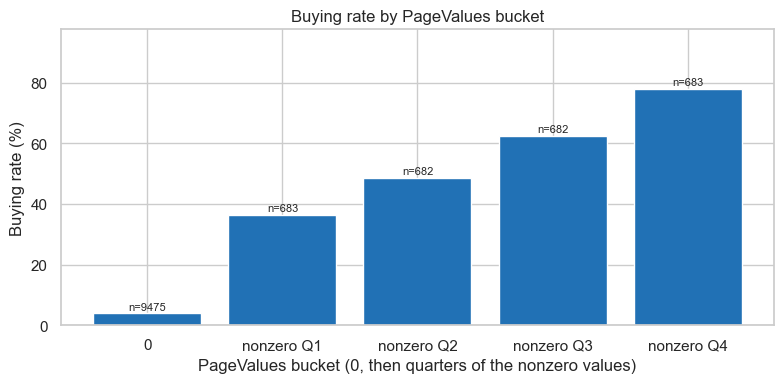

Buyers with PageValues = 0: 370 of 1908 (19.4%)


In [15]:
def bucket_buying_rate(frame, column, filename):
    correlation = frame[column].corr(frame["Revenue"])
    print(column, "correlation with Revenue:", round(correlation, 4))
    nonzero = frame.loc[frame[column] > 0, column]
    binned = pd.qcut(nonzero, 4, duplicates="drop")
    n_bins = binned.cat.categories.size
    binned = binned.cat.rename_categories([f"nonzero Q{i}" for i in range(1, n_bins + 1)])
    print("Nonzero quarter edges:")
    print(pd.qcut(nonzero, 4, duplicates="drop").cat.categories.astype(str).tolist())

    bucket = pd.Series("0", index=frame.index)
    bucket.loc[binned.index] = binned.astype(str)
    order = ["0"] + [f"nonzero Q{i}" for i in range(1, n_bins + 1)]
    grouped = frame.groupby(bucket, observed=False)["Revenue"].agg(buyers="sum", n="count")
    grouped = grouped.reindex(order)
    grouped["buying_rate"] = 100 * grouped["buyers"] / grouped["n"]
    print(grouped.round(2).to_string())

    fig, ax = plt.subplots(figsize=(8, 4))
    colors = ["#bdbdbd" if n_rows < 100 else "#2171b5" for n_rows in grouped["n"]]
    bars = ax.bar(grouped.index.astype(str), grouped["buying_rate"], color=colors)
    for bar, n_rows in zip(bars, grouped["n"]):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.6,
            f"n={int(n_rows)}",
            ha="center",
            va="bottom",
            fontsize=8,
        )
    ax.set_ylabel("Buying rate (%)")
    ax.set_xlabel(f"{column} bucket (0, then quarters of the nonzero values)")
    ax.set_title(f"Buying rate by {column} bucket")
    ax.set_ylim(0, grouped["buying_rate"].max() * 1.25)
    fig.tight_layout()
    save_and_show(fig, filename)
    return correlation, grouped


page_corr, page_buckets = bucket_buying_rate(df, "PageValues", "pagevalues_buckets")
buyers_total = int(df["Revenue"].sum())
page_zero_buyers = int(((df["PageValues"] == 0) & (df["Revenue"] == 1)).sum())
print(
    "Buyers with PageValues = 0:",
    page_zero_buyers,
    "of",
    buyers_total,
    "({:.1f}%)".format(100 * page_zero_buyers / buyers_total),
)


`PageValues` bucket rates rise from **3.91%** at zero (n = **9,475**) to **36.31%**, **48.68%**, **62.32%**, and **78.04%** across the four nonzero quarters (n = **683**, **682**, **682**, **683**). **370** of **1,908** buyers (**19.4%**) have `PageValues` = 0. This is not a proven leak. The concern comes from how the column is defined, as the average value of pages seen before a purchase, and the data alone cannot prove that. Phase 2 must test the model with and without this column.


BounceRates correlation with Revenue: -0.1451
Nonzero quarter edges:
['(-0.0009727000000000001, 0.00635]', '(0.00635, 0.0143]', '(0.0143, 0.0353]', '(0.0353, 0.2]']
            buyers     n  buying_rate
0             1036  5518        18.77
nonzero Q1     394  1673        23.55
nonzero Q2     291  1702        17.10
nonzero Q3     146  1645         8.88
nonzero Q4      41  1667         2.46


Saved: ../images/02_bouncerates_buckets.png


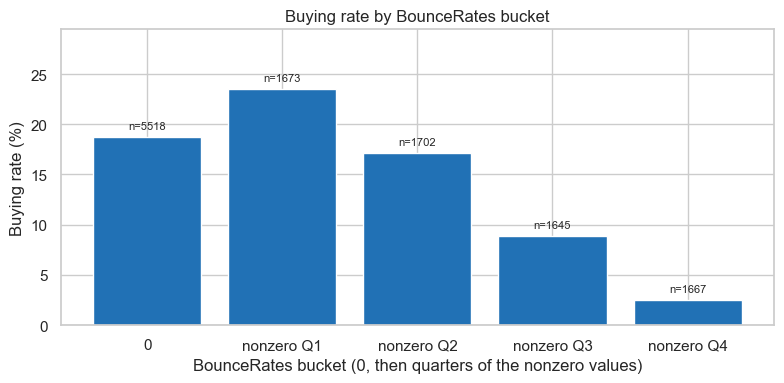

In [16]:
bounce_corr, bounce_buckets = bucket_buying_rate(df, "BounceRates", "bouncerates_buckets")


Across the nonzero `BounceRates` buckets, the buying rate falls from **23.55%** (n = **1,673**) to **17.10%** (n = **1,702**), **8.88%** (n = **1,645**), and **2.46%** (n = **1,667**). The zero bucket buys at **18.77%** (n = **5,518**), so it is not the bottom of that fall. Judge this column by these bucket rates. Pearson only measures a straight-line link.


ExitRates correlation with Revenue: -0.2043
Nonzero quarter edges:
['(-0.0008240000000000001, 0.0143]', '(0.0143, 0.025]', '(0.025, 0.0494]', '(0.0494, 0.2]']
            buyers     n  buying_rate
0               34    76        44.74
nonzero Q1     810  3103        26.10
nonzero Q2     599  2966        20.20
nonzero Q3     372  3028        12.29
nonzero Q4      93  3032         3.07


Saved: ../images/02_exitrates_buckets.png


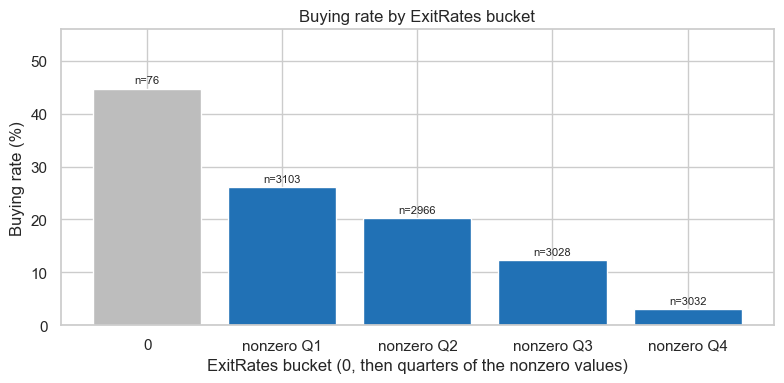

In [17]:
exit_corr, exit_buckets = bucket_buying_rate(df, "ExitRates", "exitrates_buckets")


Across the nonzero `ExitRates` buckets, the buying rate falls from **26.10%** (n = **3,103**) to **20.20%** (n = **2,966**), **12.29%** (n = **3,028**), and **3.07%** (n = **3,032**). The zero bucket is **44.74%**, but n = **76**, so that rate is unreliable. `BounceRates` and `ExitRates` both fall strongly across their nonzero buckets.


### Can a real user provide this?

A shopper cannot type `PageValues`, `BounceRates`, or `ExitRates`. Each one is calculated from the visit.

`PageValues` may leak because of its definition: it is the average value of pages seen before a purchase. The buckets rise from **3.91%** to **78.04%**, but **370** of **1,908** buyers (**19.4%**) still have `PageValues` = 0. The data alone cannot prove a leak.

`BounceRates` and `ExitRates` agree with each other on the nonzero buckets: buying falls from **23.55%** to **2.46%** for bounce, and from **26.10%** to **3.07%** for exit. That is not the same pattern as the `PageValues` rise. Do not group all three.

Decide in Phase 2 by testing the model with and without these columns.


## Insights

- **15.63%** of the 12,205 visits bought (1,908 buyers). A guess of "nobody buys" would be right **84.37%** of the time, so accuracy is a poor score.
- November is linked with buying: **25.49%** bought (760 buyers, 2,982 rows). November is **24.43%** of all rows and **39.83%** of all buyers.
- The file is one year of visits, with no January and no April, and no visitor ID. February has **3** buyers in 181 rows, and June has **29** buyers in 285 rows. Both are under 30 buyers, so those two month rates are unreliable.
- ProductRelated pages above 0 with time equal to 0: **7** buyers in **592** rows (**1.18%**). Administrative zero-time rows buy at **25.19%** (n = 135) and Informational zero-time rows buy at **21.24%** (n = 226). The three types do not agree.
- Two pairs of inputs are tightly linked with each other: BounceRates with ExitRates (Pearson **0.90**) and ProductRelated with ProductRelated_Duration (Pearson **0.86**). No third pair reaches 0.70.
- A nonzero SpecialDay score appears only in February (79 rows) and May (1,170 rows). Inside May, a score of 0 is linked with a **13.43%** buying rate (290 buyers, n = 2,159) and a nonzero score with **6.41%** (75 buyers, n = 1,170). February has only 3 buyers, so its split is unreliable. The all-year gap (16.71% versus 6.16%) mixes in months that never have a special-day score.
- New visitors are linked with a higher buying rate than returning visitors: **24.93%** (422 of 1,693) versus **14.09%** (1,470 of 10,431).
- PageValues is linked with buying. The zero bucket buys at **3.91%** (n = 9,475). The four nonzero quarters buy at **36.31%**, **48.68%**, **62.32%**, and **78.04%**. Still, **370** of **1,908** buyers (**19.4%**) have PageValues = 0.
- Across the nonzero buckets, BounceRates is linked with a falling buying rate: **23.55%**, **17.10%**, **8.88%**, **2.46%**. ExitRates falls the same way: **26.10%**, **20.20%**, **12.29%**, **3.07%**.
- Among traffic codes with at least 100 rows, code 8 is linked with a **27.70%** buying rate (n = 343) and code 13 with **5.91%** (n = 728).

## What this means for modeling

- Do not judge a model by accuracy alone. Saying "nobody buys" is already right 84.37% of the time.
- Keep the buyer share in mind when the data is split later. Buyers are 15.63% of rows.
- Month is a season label for one year, not a trend. Do not trust February or June rates (3 and 29 buyers).
- There is no visitor ID, so the same person cannot be tracked across visits.
- ProductRelated and its duration move together (0.86). BounceRates and ExitRates move together (0.90). A model may not need both columns from a pair.
- Do not treat the all-year SpecialDay chart as a clean effect. The fair comparison is inside May: 13.43% versus 6.41%.
- Keep the zero-time rows. The three page types do not show the same buying rate.
- PageValues, BounceRates, and ExitRates stay in for now. Phase 2 tests the model with and without them.

## Can a real user provide this?

- **Hard for a shopper to type.** PageValues, BounceRates, and ExitRates are all calculated from the visit. A shopper does not type them.
- **PageValues may leak.** It is defined as the average value of pages seen before a purchase. Bucket rates rise from **3.91%** at zero to **78.04%** in the top quarter. **370** of **1,908** buyers (**19.4%**) still have PageValues = 0, so it is not a perfect flag. The data alone cannot prove a leak.
- **BounceRates and ExitRates are a different pattern.** Both fall strongly across the nonzero buckets: bounce from **23.55%** to **2.46%**, exit from **26.10%** to **3.07%**. That is a link with buying. It is not the same rising pattern as PageValues, so these two are not grouped with PageValues.
- Decide in Phase 2 by testing the model with and without these columns.
